error time t: 0.05
error theta:  

In [9]:
import numpy as np

In [10]:
t1 = np.array([1.85, 3.32, 4.69, 6.10, 7.52, 8.94, 10.36, 11.79, 13.20, 14.57])
a1 = np.array([875, 862, 858, 852, 847, 843, 837, 833, 827, 824])               

In [11]:
t2 = np.array([1.67, 3.04, 4.46, 5.88, 7.30, 8.72, 10.19, 11.61, 13.03, 14.40])
a2 = np.array([743, 715, 686, 651, 629, 612, 601, 594, 591, 580])               

In [12]:
T1 = np.array([t1[i+1] - t1[i] for i in range(len(t1)-1)])  
T2 = np.array([t2[i+1] - t2[i] for i in range(len(t2)-1)])  

In [13]:
print(T1)
print(T2)

[1.47 1.37 1.41 1.42 1.42 1.42 1.43 1.41 1.37]
[1.37 1.42 1.42 1.42 1.42 1.47 1.42 1.42 1.37]


In [14]:
meanT1 = np.mean(T1)  
meanT2 = np.mean(T2)  
print(meanT1, meanT2)

1.4133333333333333 1.4144444444444444


In [55]:
sigma_T1 = np.std(T1, ddof=1)
print(sigma_T1)


0.03041381265149075


In [56]:
sigma_T2 = np.std(T2, ddof=1)
print(sigma_T2)


0.03004626062886612


### Stimare I

In [48]:
L_rod = 0.48
M_rod = (L_rod * 0.008**2) * 2700  
I_rod = 1/3 *L_rod**2 * M_rod






R_ball = 0.065/2
M_ball = (np.pi * R_ball**2 * 0.012) * 8500

I_ball_c = 1/2 * M_ball * (R_ball)**2
I_ball_pivot = I_ball_c + M_ball * (R_ball+L_rod)**2

In [49]:
w0 = np.sqrt((M_rod+M_ball)*9.81*L_rod/(I_rod+I_ball_pivot))

In [50]:
print(w0)

4.559545953527828


### Stimare damping

In [63]:
t2s = [x-1.67 for x in t2]  
print(t2s)  
theta0 = t2s[0]  

[0.0, 1.37, 2.79, 4.21, 5.63, 7.050000000000001, 8.52, 9.94, 11.36, 12.73]


In [22]:
from scipy.stats import linregress

log_theta = np.log(a2)

# Linear fit
slope, intercept, r_value, p_value, std_err = linregress(t2s, log_theta)

# Extract tau
tau = -1 / slope

print(f"Estimated tau: {tau}")

Estimated tau: 51.590637739950246


In [102]:
from scipy.stats import linregress

t1s = [x-t2[0] for x in t2]  


log_theta = np.log(a1)

# Linear fit
slope, intercept, r_value, p_value, std_err = linregress(t1s, log_theta)

# Extract tau
tau = -1 / slope

print(f"Estimated tau: {tau}")

Estimated tau: 226.42561901539847


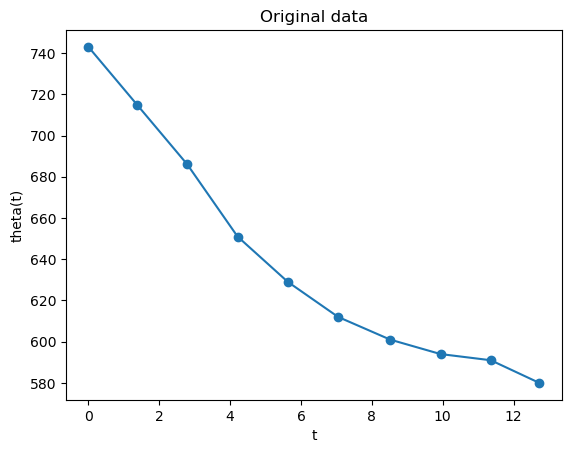

In [23]:
import matplotlib.pyplot as plt
plt.plot(t2s, a2, 'o-')
plt.xlabel('t')
plt.ylabel('theta(t)')
plt.title('Original data')
plt.show()

In [65]:
t_data = [x-t2[0] for x in t2]
theta_data = a2
theta0 = theta_data[0]

In [66]:
def decay_model(t, tau):
    return theta0 * np.exp(-t / tau)

In [68]:
from scipy.optimize import curve_fit

popt, pcov = curve_fit(decay_model, t_data, theta_data)
tau_fit = popt[0]
print(f"Fitted tau: {tau_fit}")

Fitted tau: 43.488109207771224


In [100]:
sigma_x = np.full(10, 0.3)
sigma_y = np.full(10, 20)

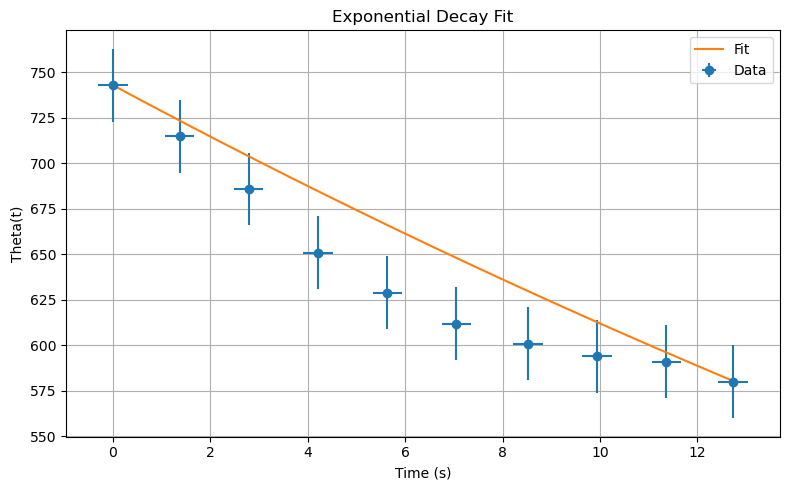

In [101]:

# Generate smooth curve using the fitted tau
t_fit = np.linspace(np.min(t_data), np.max(t_data), 300)
theta_fit = decay_model(t_fit, tau_fit)

# Plot
plt.figure(figsize=(8, 5))
plt.errorbar(t_data, theta_data, fmt='o', xerr=sigma_x, yerr=sigma_y, label='Data')
plt.plot(t_fit, theta_fit, '-', label=f'Fit')
plt.xlabel('Time (s)')
plt.ylabel('Theta(t)')
plt.title('Exponential Decay Fit')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Fitted tau (linearized): 51.590637739950246


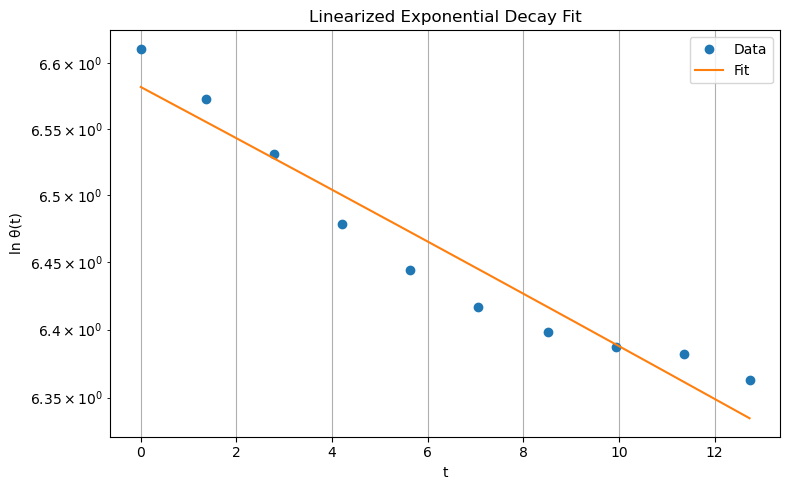

In [81]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Filter out any zero or negative theta values (log is undefined)
valid = theta_data
t_valid = t_data
log_theta = np.log(theta_data)

# Linear regression
slope, intercept, r_value, p_value, std_err = linregress(t_valid, log_theta)
tau_fit = -1 / slope
print(f"Fitted tau (linearized): {tau_fit}")

# Generate fit line
t_fit = np.linspace(np.min(t_valid), np.max(t_valid), 300)
log_theta_fit = slope * t_fit + intercept

# Plot
plt.figure(figsize=(8,5))
plt.plot(t_valid, log_theta, 'o', label='Data')
plt.plot(t_fit, log_theta_fit, '-', label=f'Fit')
plt.xlabel('t')
plt.ylabel('ln θ(t)')
plt.title('Linearized Exponential Decay Fit')
plt.legend()
plt.grid(True)

plt.yscale('log')
plt.tight_layout()
plt.show()


### Fase e controfase

In [26]:
tf = [13.28, 14.70, 16.01, 17.43, 18.86, 20.28, 21.69, 23.11, 24.53, 25.95]
af = [657, 649, 638, 632, 624, 612, 600, 590, 585, 577]
Tf = np.array([tf[i+1] - tf[i] for i in range(len(tf)-1)])  

In [27]:
meanTf = np.mean(Tf)  
sigma_Tf = np.std(Tf, ddof=1)

pulsef = 2 * np.pi / meanTf  
sigma_pulsef = 2 * np.pi / (meanTf**2) * sigma_Tf

In [29]:
tc = [5.22, 6.59, 7.97, 9.32, 10.69, 12.01, 13.38, 14.75, 16.12, 17.54]
Tc = np.array([tc[i+1] - tc[i] for i in range(len(tc)-1)])  

In [30]:
meanTc = np.mean(Tc)  
sigma_Tc = np.std(Tc, ddof=1)

pulsec = 2 * np.pi / meanTc  
sigma_pulsec = 2 * np.pi / (meanTc**2) * sigma_Tc

In [31]:
print(pulsef)
print(pulsec)

4.463193983000496
4.589989266608464


In [57]:
print(sigma_pulsef)

0.1173231910410754


In [53]:
pulse0 = 2 * np.pi / meanT1
print(pulse0) 

sigma_T1 = np.std(T1, ddof=1)

sigma_pulse0 = 2 * np.pi / (meanT1**2) * sigma_T1

4.445649981494991


In [54]:
print(sigma_pulse0)

0.09566686248912167


In [ ]:
sigma_pulsec = 2 * np.pi / (meanT1**2) * sigma_T1

### Battimenti

In [33]:
tp = [6.18, 7.55, 8.97, 10.34, 11.76, 13.08, 14.49, 15.86, 17.44, 19.26]
Tp = np.array([tp[i+1] - tp[i] for i in range(len(tp)-1)])  

In [37]:
meanTp = np.mean(Tp)  
sigma_Tp = np.std(Tp, ddof=1)

pulsep = 2 * np.pi / meanTp  
sigma_pulsep = 2 * np.pi / (meanTp**2) * sigma_Tp

In [35]:
tm = [4.73, 45.3, 79.2, 113, 146]
Tm = np.array([tm[i+1] - tm[i] for i in range(len(tm)-1)])  

In [58]:
meanTm = np.mean(Tm)  
sigma_Tm = np.std(Tm, ddof=1)

pulsem = 2 * np.pi / meanTm  
sigma_pulsem = 2 * np.pi / (meanTm**2) * sigma_Tm

In [59]:
print(pulsep)
print(pulsem)

4.32329264255476
0.17790572116315104


In [61]:
print(sigma_Tm)

3.5247541285409736
